<a href="https://colab.research.google.com/github/Saransh-Basu-01/50-Ml-Projects-to-understand-LLMs/blob/main/Project_26_Current_Layer%3DPrevious_layer_%2B_Adjustments.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import pearsonr,spearmanr

import torch

from transformers import AutoModelForCausalLM, AutoTokenizer

# Part_1:Hooks and Hidden_State

## Task_1:
- Import GPT-2-small, implant the hook function shown above into
transformer layer 5, and tokenize the following text (it’s also printed
in the online code file): Plants make fantastic pets because they don’t
leave a mess after you feed them.
Call a forward pass and remove the hook.
Check that the shape of the tensor stored in the transf_out
dictionary matches that of the output of the hidden states. Pick
one embeddings dimension and make a scatter plot of the value in
that dimension for both the hidden state and the transformer output
(Figure 5.16). The data points should overlap because they both
access the same data.
After the visual confirmation for one embeddings dimension,
subtract the hidden-state tensor from the transformer output tensor,
and confirm that the difference matrix is all zeros.

In [2]:
tokenizer = AutoTokenizer.from_pretrained('gpt2')
model = AutoModelForCausalLM.from_pretrained('gpt2',output_hidden_states=True)
model.eval()

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

[transformers] The following generation flags are not valid and may be ignored: ['output_hidden_states']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 768)
    (wpe): Embedding(1024, 768)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-11): 12 x GPT2Block(
        (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=2304, nx=768)
          (c_proj): Conv1D(nf=768, nx=768)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=3072, nx=768)
          (c_proj): Conv1D(nf=768, nx=3072)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
  )
  (lm_head): Linear(in_features=768, out_features=50257, bias=False)
)

In [9]:
# initialize the dictionary containing data
transf_out = {}

# the hook function
def hook(module, input, output):
  # module: the layer the hook is attached to
  # input : inputs passed into that layer during the forward pass
  # output: output of that layer
  transf_out['data'] = output.detach()

# implant the hook
layi = 5
handle = model.transformer.h[layi].register_forward_hook(hook)

In [7]:
model.transformer.h

ModuleList(
  (0-11): 12 x GPT2Block(
    (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
    (attn): GPT2Attention(
      (c_attn): Conv1D(nf=2304, nx=768)
      (c_proj): Conv1D(nf=768, nx=768)
      (attn_dropout): Dropout(p=0.1, inplace=False)
      (resid_dropout): Dropout(p=0.1, inplace=False)
    )
    (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
    (mlp): GPT2MLP(
      (c_fc): Conv1D(nf=3072, nx=768)
      (c_proj): Conv1D(nf=768, nx=3072)
      (act): NewGELUActivation()
      (dropout): Dropout(p=0.1, inplace=False)
    )
  )
)

In [8]:
model.transformer.h[5]

GPT2Block(
  (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
  (attn): GPT2Attention(
    (c_attn): Conv1D(nf=2304, nx=768)
    (c_proj): Conv1D(nf=768, nx=768)
    (attn_dropout): Dropout(p=0.1, inplace=False)
    (resid_dropout): Dropout(p=0.1, inplace=False)
  )
  (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
  (mlp): GPT2MLP(
    (c_fc): Conv1D(nf=3072, nx=768)
    (c_proj): Conv1D(nf=768, nx=3072)
    (act): NewGELUActivation()
    (dropout): Dropout(p=0.1, inplace=False)
  )
)

In [10]:

text = "Plants make fantastic pets because they don't leave a mess after you feed them."
tokens = tokenizer.encode(text,return_tensors="pt")

# forward pass to trigger the hook
with torch.no_grad():
  outputs =model(tokens)

# remove the hook
handle.remove()

In [13]:
print('     Hidden states is size:',outputs.hidden_states[layi+1].shape)
print('Transformer output is size:',transf_out['data'].shape)

     Hidden states is size: torch.Size([1, 17, 768])
Transformer output is size: torch.Size([1, 17, 768])


In [20]:
outputs.hidden_states[6]

tensor([[[-0.0448, -2.6673, -0.8086,  ..., -0.4345, -1.0803, -0.4612],
         [-0.7582,  0.2152, -0.1291,  ...,  0.6818, -0.6248,  0.5173],
         [ 0.6731, -1.9390, -0.5297,  ...,  1.9940, -2.2004, -1.6972],
         ...,
         [ 0.3338, -1.8965, -5.4044,  ..., -4.9260, -1.0576, -1.8959],
         [-0.8103,  2.2054, -5.0447,  ...,  1.5602,  0.4215, -1.5921],
         [ 0.8897, -1.8465, -0.7044,  ..., -0.1974, -1.7365, -0.1480]]])

In [17]:
transf_out

{'data': tensor([[[-0.0448, -2.6673, -0.8086,  ..., -0.4345, -1.0803, -0.4612],
          [-0.7582,  0.2152, -0.1291,  ...,  0.6818, -0.6248,  0.5173],
          [ 0.6731, -1.9390, -0.5297,  ...,  1.9940, -2.2004, -1.6972],
          ...,
          [ 0.3338, -1.8965, -5.4044,  ..., -4.9260, -1.0576, -1.8959],
          [-0.8103,  2.2054, -5.0447,  ...,  1.5602,  0.4215, -1.5921],
          [ 0.8897, -1.8465, -0.7044,  ..., -0.1974, -1.7365, -0.1480]]])}

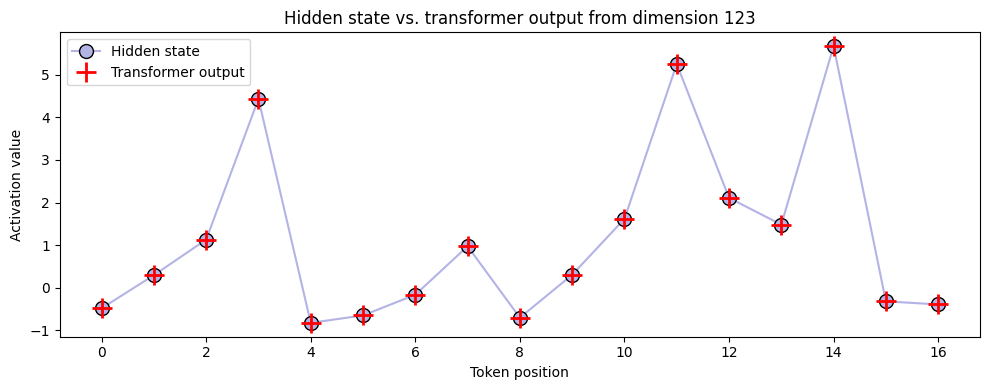

In [21]:
plt.figure(figsize=(10,4))

dimnum = 123

plt.plot(outputs.hidden_states[layi+1][0,:,dimnum],'o-',markeredgecolor='k',
         color=[.7,.7,.9],markerfacecolor=[.7,.7,.9],markersize=10,label='Hidden state')
plt.plot(transf_out['data'][0,:,dimnum],'r+',markersize=14,markeredgewidth=2,label='Transformer output')

plt.gca().set(xlabel='Token position',ylabel='Activation value',title=f'Hidden state vs. transformer output from dimension {dimnum}')
plt.legend()

plt.tight_layout()
plt.show()

In [22]:
# differences are zeros
outputs.hidden_states[layi+1] - transf_out['data']

tensor([[[0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         ...,
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.],
         [0., 0., 0.,  ..., 0., 0., 0.]]])